# Course 4 — Extended Experiments: Stronger Evidence and Improvements

The main experiment (notebook 03) follows the synopsis exactly but has three weaknesses:
1. only **20 test events**, so DQN vs the heuristics is not statistically decidable;
2. channels 41/43/45 have ~50× larger reconstruction errors than the others even on clean data,
   so raw errors hide what is *unusual* for the smaller channels;
3. the LSTM-AE window detector has modest recall (0.40), so 38 / 168 events never reach the RL stage.

This notebook addresses them **without touching the test data during any choice**:
* **A. Channel-normalised anomaly scores.** Each channel error is divided by that channel's median error on
  label-clean *training* windows (no labels needed). Three window scores are compared on validation PR-AUC;
  the best is adopted only if it beats the original on validation.
* **B. 5-fold cross-validation over events.** Every investigation case is tested exactly once
  (≈ 6× more test cases), 5 DQN seeds per fold, checkpoint chosen on an inner validation split.
* **C. Ablation.** (i) original detector + raw-error state (= notebook 03 setup), (ii) original detector +
  normalised state, (iii) improved detector + normalised state.
* **D. Budget sweep** 3 / 5 / 7 for the best configuration.

In [1]:
import os, sys, json, time, random
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
import multiprocessing as mp
from scipy.stats import wilcoxon
from sklearn.metrics import precision_recall_curve, average_precision_score, roc_auc_score, f1_score, precision_score, recall_score

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf

PROJECT = Path.cwd().parent
sys.path.insert(0, str(PROJECT / "src"))
import rl_utils as U
import dqn_core as D

OUT = PROJECT / "outputs"; LSTM_DIR = OUT / "05_lstm_autoencoder"; PLOTS = OUT / "04_plots"
EXT = OUT / "09_extended_experiments"; EXT.mkdir(parents=True, exist_ok=True)
SEED = 42; random.seed(SEED); np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.grid": True, "grid.alpha": 0.3})
def save_show(name):
    plt.tight_layout(); plt.savefig(PLOTS / name, bbox_inches="tight"); plt.close()
    display(Image(filename=str(PLOTS / name)))

I0000 00:00:1794215482.272305     433 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794215483.355180     433 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Load data, model and window scores from notebooks 01–03

In [2]:
telemetry_df = pd.read_parquet(OUT / "02_preprocessing" / "telemetry_90s_12channels.parquet")
labels = pd.read_csv(OUT / "01_dataset" / "selected_anomaly_labels.csv", parse_dates=["StartTime", "EndTime"])
split_ids = pd.read_csv(OUT / "03_splits" / "anomaly_event_split.csv")
seg = pd.read_csv(LSTM_DIR / "clean_segment_split.csv", parse_dates=["Start", "End"])
cfg_lstm = json.load(open(LSTM_DIR / "lstm_config.json"))
stats = pd.read_csv(LSTM_DIR / "training_normalization_statistics.csv")
ae = tf.keras.models.load_model(LSTM_DIR / "lstm_autoencoder.keras")
win = pd.read_parquet(OUT / "06_rl_dqn" / "lstm_window_scores.parquet")
CHANNELS = list(telemetry_df.columns); N_CH = len(CHANNELS)
mu, sd = stats["Mean"].to_numpy(), stats["Std"].to_numpy()
WINDOW, CLIP, THR0 = cfg_lstm["window"], cfg_lstm["clip_sigma"], cfg_lstm["threshold"]
values = telemetry_df.to_numpy(np.float32); index = telemetry_df.index
n_global = len(values) // WINDOW
event_sets = labels.groupby("ID")["Channel"].apply(set).to_dict()
print("Windows scored:", len(win), "| events:", len(event_sets))

Windows scored: 38328 | events: 168


## 2. A — Channel-normalised anomaly scores (choice made on validation only)

   Channel  Clean-train median error
channel_41                   0.05245
channel_45                   0.05269
channel_43                   0.04551
channel_14                   0.00089
channel_21                   0.00089
channel_29                   0.00088
channel_48                   0.00413
channel_52                   0.00879
channel_31                   0.00089
channel_22                   0.00087
channel_39                   0.00095
channel_15                   0.00098


              Score      Split  PR_AUC  ROC_AUC  Precision  Recall     F1
Mean MSE (original) Validation  0.6359   0.8100     0.7991  0.4946 0.6110
Mean MSE (original)       Test  0.5174   0.7446     0.7481  0.3992 0.5206
     Mean log-ratio Validation  0.6535   0.8108     0.8137  0.5311 0.6427
     Mean log-ratio       Test  0.6159   0.8205     0.7348  0.4908 0.5885
      Max log-ratio Validation  0.6694   0.8063     0.9136  0.5284 0.6695
      Max log-ratio       Test  0.6282   0.8193     0.9157  0.4644 0.6162

Selected on validation PR-AUC: Max log-ratio (threshold 1.9219)


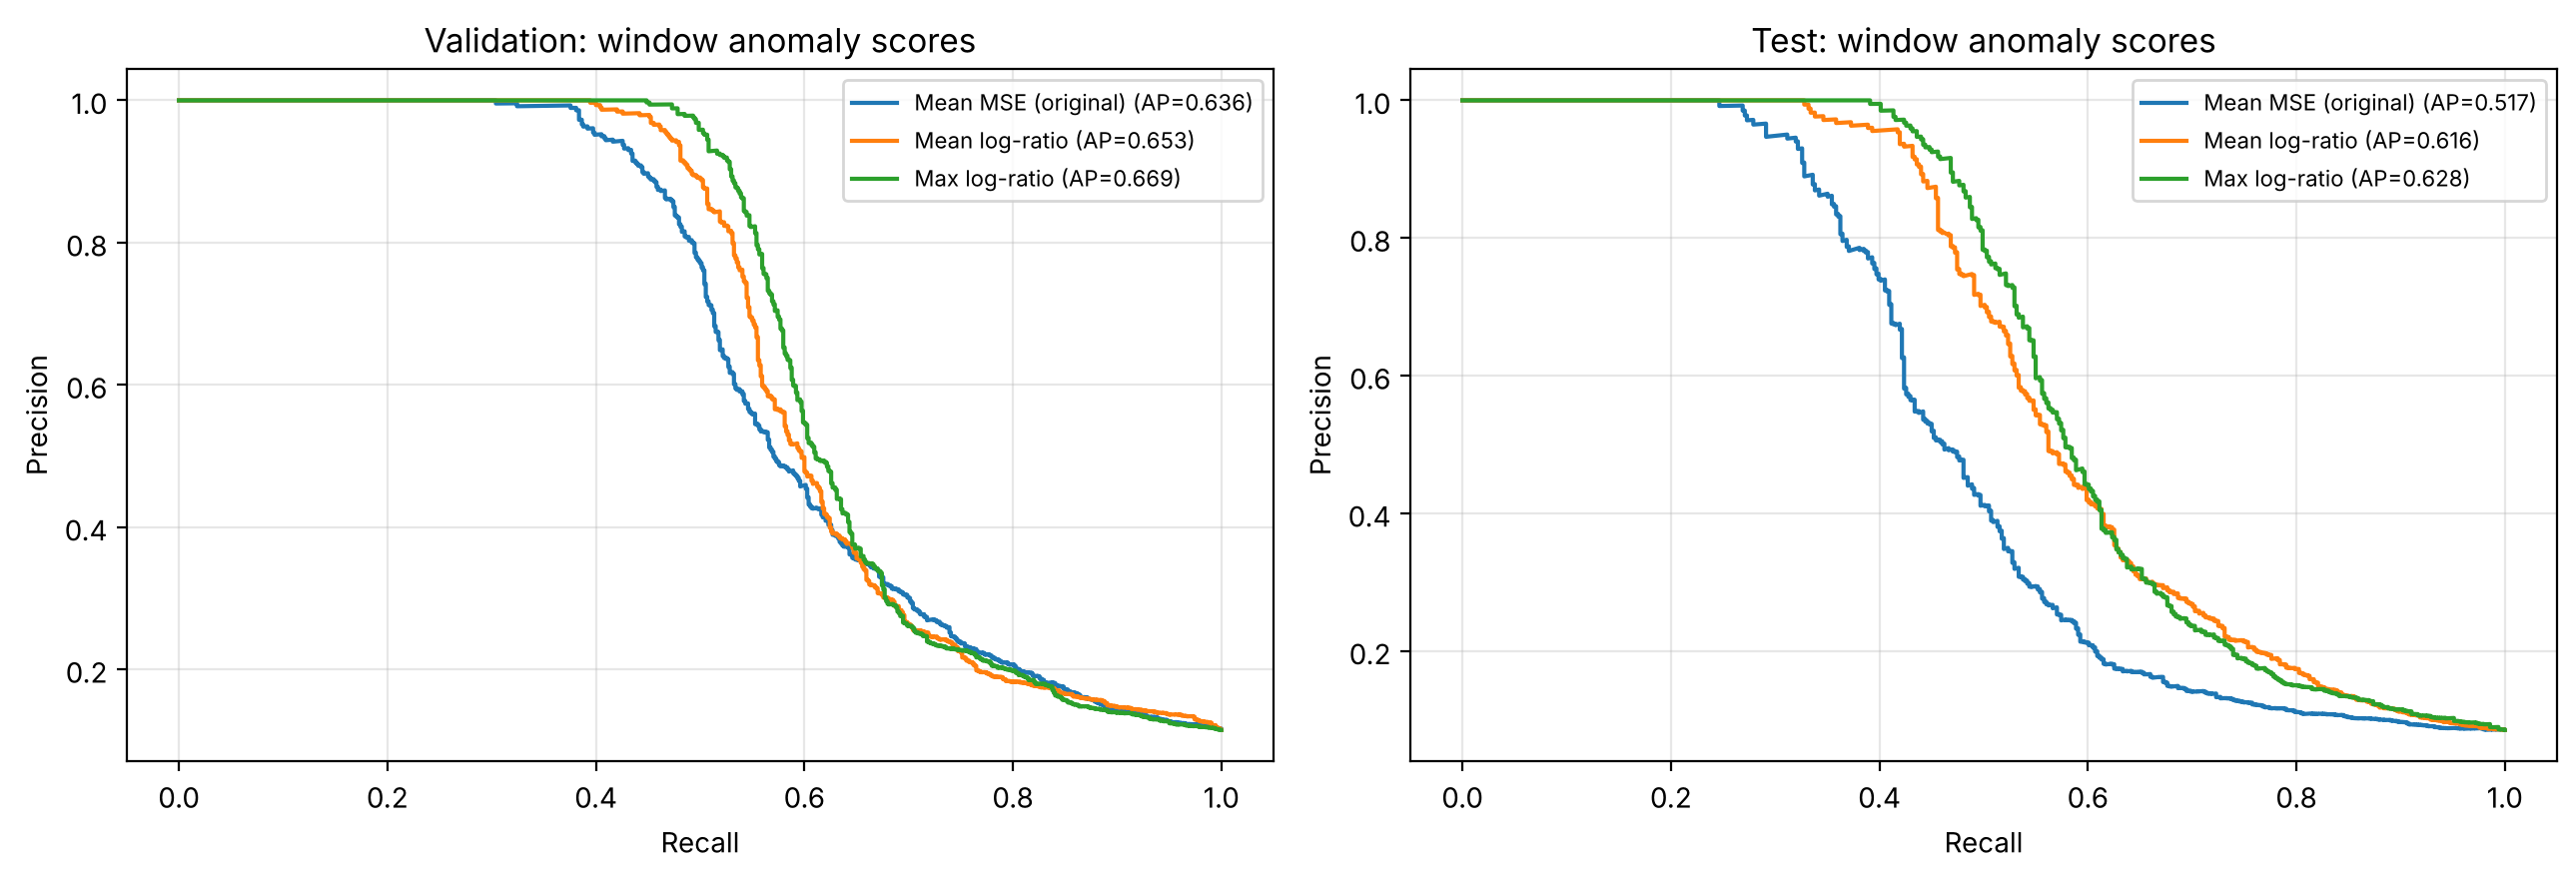

In [3]:
def clean_windows(split):
    out = []
    for s, e in zip(index.searchsorted(seg.loc[seg.Split == split, "Start"]), index.searchsorted(seg.loc[seg.Split == split, "End"], side="right")):
        k = (e - s) // WINDOW
        if k:
            w = values[s:s + k * WINDOW].reshape(k, WINDOW, N_CH); out.append(w[~np.isnan(w).any(axis=(1, 2))])
    return np.concatenate(out)

def channel_errors(x):
    xn = np.clip((x - mu) / sd, -CLIP, CLIP).astype(np.float32)
    return np.mean((xn - ae.predict(xn, batch_size=1024, verbose=0)) ** 2, axis=1)

ref_median = np.median(channel_errors(clean_windows("Train")), axis=0)      # label-free channel reference level
print(pd.DataFrame({"Channel": CHANNELS, "Clean-train median error": ref_median}).to_string(index=False, float_format="%.5f"))

gwin_ids = win.WindowID.to_numpy()
def anomaly_window_rows(split):
    ids = set(split_ids.loc[split_ids.Split == split, "ID"]); lab = labels[labels.ID.isin(ids)]
    m = U.interval_mask(index, lab.StartTime.values, lab.EndTime.values)[:n_global * WINDOW].reshape(n_global, WINDOW).any(1)
    return win[m[gwin_ids]]

SCORES = {
    "Mean MSE (original)": lambda E: E.mean(axis=1),
    "Mean log-ratio": lambda E: np.log(E / ref_median).mean(axis=1),
    "Max log-ratio": lambda E: np.log(E / ref_median).max(axis=1),
}
data = {}
for split in ["Validation", "Test"]:
    Ec = channel_errors(clean_windows(split)); Ea = anomaly_window_rows(split)[CHANNELS].to_numpy()
    data[split] = (np.vstack([Ec, Ea]), np.r_[np.zeros(len(Ec), int), np.ones(len(Ea), int)])

rows, thr = [], {}
for name, f in SCORES.items():
    E, y = data["Validation"]; s = f(E)
    p, r, t = precision_recall_curve(y, s); f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12); thr[name] = float(t[np.argmax(f1)])
    for split in ["Validation", "Test"]:
        E, y = data[split]; s = f(E); pred = s >= thr[name]
        rows.append({"Score": name, "Split": split, "PR_AUC": average_precision_score(y, s), "ROC_AUC": roc_auc_score(y, s),
                     "Precision": precision_score(y, pred), "Recall": recall_score(y, pred), "F1": f1_score(y, pred)})
det_cmp = pd.DataFrame(rows)
print(det_cmp.round(4).to_string(index=False))
val_auc = det_cmp[det_cmp.Split == "Validation"].set_index("Score")["PR_AUC"]
BEST = val_auc.idxmax()
if val_auc[BEST] <= val_auc["Mean MSE (original)"]: BEST = "Mean MSE (original)"
print(f"\nSelected on validation PR-AUC: {BEST} (threshold {thr[BEST]:.4f})")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, split in zip(ax, ["Validation", "Test"]):
    E, y = data[split]
    for name, f in SCORES.items():
        p, r, _ = precision_recall_curve(y, f(E)); a.plot(r, p, label=f"{name} (AP={average_precision_score(y, f(E)):.3f})")
    a.set_xlabel("Recall"); a.set_ylabel("Precision"); a.set_title(f"{split}: window anomaly scores"); a.legend(fontsize=8)
save_show("16_detector_score_comparison.png")

## 3. Investigation cases for both detectors

In [4]:
E_all = win[CHANNELS].to_numpy()
event_masks = {}
for eid, g in labels.groupby("ID"):
    m = U.interval_mask(index, g.StartTime.values, g.EndTime.values)[:n_global * WINDOW].reshape(n_global, WINDOW).any(1)
    event_masks[eid] = m[gwin_ids]

def build_cases(score_name):
    s = SCORES[score_name](E_all); det = s >= thr[score_name]
    rows = []
    for eid, m in event_masks.items():
        c = np.where(det & m)[0]
        if len(c):
            k = c[np.argmax(s[c])]
            rows.append({"EventID": eid, "WindowID": int(win.WindowID.iloc[k]), "Score": float(s[k]), **dict(zip(CHANNELS, E_all[k]))})
    return pd.DataFrame(rows)

cases_orig = build_cases("Mean MSE (original)"); cases_best = build_cases(BEST)
print(f"Events with a detected window: original detector {len(cases_orig)} / 168, selected detector ({BEST}) {len(cases_best)} / 168")

def state_raw(c): return np.log1p(c[CHANNELS].to_numpy(np.float32))
def state_norm(c): return np.log1p(c[CHANNELS].to_numpy(np.float32) / ref_median).astype(np.float32)
def targets(c): return np.array([[ch in event_sets[e] for ch in CHANNELS] for e in c.EventID], bool)

Events with a detected window: original detector 130 / 168, selected detector (Max log-ratio) 116 / 168


## 4. B — 5-fold cross-validation over events (5 DQN seeds per fold, trained in parallel)

In [5]:
HP = dict(hidden=64, lr=1e-3, gamma=0.95, batch=64, buffer=10000, episodes=int(os.environ.get("EXT_EPISODES", 3000)), eps_start=1.0, eps_min=0.05,
          eps_decay=0.998, target_update=20, eval_every=50)
SEEDS = [0, 1, 2, 3, 4]; K = 5

def make_folds(n, seed=SEED):
    perm = np.random.RandomState(seed).permutation(n); return [perm[i::K] for i in range(K)]

def static_metrics(sel, y, b):
    return D.episode_metrics(np.array(sel[:b]), y)

def run_cv(cases, state_fn, budget, tag, seeds=SEEDS):
    S, Y = state_fn(cases), targets(cases); S_raw = state_raw(cases); folds = make_folds(len(cases))
    cfgs, meta = [], []
    for k, te in enumerate(folds):
        rest = np.setdiff1d(np.arange(len(cases)), te)
        rest = np.random.RandomState(100 + k).permutation(rest); n_va = max(1, int(round(len(rest) * 0.2)))
        va, tr = rest[:n_va], rest[n_va:]
        meta.append((k, tr, va, te))
        for s in seeds:
            cfgs.append(dict(HP, budget=budget, seed=s, train_scores=S[tr], train_targets=Y[tr], val_scores=S[va],
                             val_targets=Y[va], out_dir=str(EXT / "models"), _fold=k))
    (EXT / "models").mkdir(exist_ok=True)
    t0 = time.time()
    with mp.get_context("spawn").Pool(5) as pool:
        runs = pool.map(D.train_seed, [{k_: v for k_, v in c.items() if k_ != "_fold"} | {"seed": c["seed"] + 1000 * c["_fold"]} for c in cfgs])
    rows = []
    for (k, tr, va, te), i0 in zip(meta, range(0, len(runs), len(seeds))):
        freq = Y[np.r_[tr, va]].sum(0); fixed = list(np.argsort(-freq, kind="stable"))
        for r_ in runs[i0:i0 + len(seeds)]:
            q = D.build_q_network(tf); q.set_weights(r_["weights"])
            for i, m in zip(te, D.evaluate(lambda x: q(x, training=False).numpy(), S[te], Y[te], budget)):
                rows.append(dict(m, Method="DQN", Seed=r_["seed"], Case=int(i), Fold=k))
        for i in te:
            n_ann = int(Y[i].sum())
            rows.append(dict(static_metrics(fixed, Y[i], budget), Method="Fixed Priority", Seed=-1, Case=int(i), Fold=k))
            rows.append(dict(static_metrics(list(np.argsort(-S_raw[i], kind="stable")), Y[i], budget), Method="LSTM-Greedy", Seed=-1, Case=int(i), Fold=k))
            rows.append(dict(static_metrics(list(np.argsort(~Y[i], kind="stable")), Y[i], budget), Method="Oracle", Seed=-1, Case=int(i), Fold=k))
            eh = n_ann * budget / N_CH       # exact expectation of a uniformly random 'budget'-subset
            rows.append(dict(Hits=eh, Steps=budget, TotalReward=2 * eh - budget, Precision_at_5=eh / budget, Recall_at_5=eh / n_ann,
                             UnnecessaryInvestigations=budget - eh, Method="Random", Seed=-1, Case=int(i), Fold=k))
    df = pd.DataFrame(rows); df["Config"] = tag; df["Budget"] = budget
    df["EventID"] = cases.EventID.to_numpy()[df.Case]; df["N_annotated"] = Y.sum(1)[df.Case]
    det = df[df.Method != "Random"]
    assert np.allclose(det.TotalReward, 2 * det.Hits - budget)
    df.attrs["inner_val_reward"] = float(np.mean([r_["best_val_reward"] for r_ in runs]))
    print(f"{tag} | budget {budget}: {len(cases)} cases, {len(runs)} DQN trainings in {(time.time()-t0)/60:.1f} min"
          f" | mean inner-validation reward {df.attrs['inner_val_reward']:.3f}")
    return df

ORDER = ["DQN", "Fixed Priority", "LSTM-Greedy", "Random", "Oracle"]
MET = ["TotalReward", "Hits", "Precision_at_5", "Recall_at_5", "UnnecessaryInvestigations"]
def summarise(df):
    out = []
    for m in ORDER:
        d = df[df.Method == m]
        if m == "DQN":
            ps = d.groupby("Seed")[MET].mean()      # per seed (seed ids differ per fold; seed index = Seed % 1000)
            ps = d.assign(S=d.Seed % 1000).groupby("S")[MET].mean()
            row = {k: ps[k].mean() for k in MET} | {f"{k}_std": ps[k].std(ddof=0) for k in MET}
        else:
            row = {k: d[k].mean() for k in MET} | {f"{k}_std": 0.0 for k in MET}
        out.append({"Method": m, "Cases": d.Case.nunique()} | row)
    return pd.DataFrame(out)

def paired_tests(df):
    dq = df[df.Method == "DQN"].groupby("Case")["Hits"].mean(); res = []
    rng = np.random.RandomState(SEED)
    for o in ["Fixed Priority", "LSTM-Greedy", "Random"]:
        ob = df[df.Method == o].set_index("Case")["Hits"].reindex(dq.index); diff = (dq - ob).to_numpy()
        boots = [rng.choice(diff, len(diff)).mean() for _ in range(5000)]
        res.append({"Comparison": f"DQN vs {o}", "Mean_hit_diff": diff.mean(), "CI95_low": np.percentile(boots, 2.5),
                    "CI95_high": np.percentile(boots, 97.5), "DQN_better": int((diff > 1e-9).sum()), "Equal": int((np.abs(diff) <= 1e-9).sum()),
                    "DQN_worse": int((diff < -1e-9).sum()), "Wilcoxon_p": wilcoxon(diff, zero_method="zsplit").pvalue if np.any(diff != 0) else 1.0})
    return pd.DataFrame(res)

### C — Ablation at budget 5

In [6]:
configs = {
    "(i) original detector + raw state": (cases_orig, state_raw),
    "(ii) original detector + normalised state": (cases_orig, state_norm),
    "(iii) selected detector + normalised state": (cases_best, state_norm),
}
if BEST == "Mean MSE (original)":
    configs.pop("(iii) selected detector + normalised state")
cv = {name: run_cv(c, f, 5, name) for name, (c, f) in configs.items()}
abl = pd.concat([summarise(df).assign(Config=name) for name, df in cv.items()])
tests = pd.concat([paired_tests(df).assign(Config=name) for name, df in cv.items()])
show = ["Config", "Method", "Cases", "TotalReward", "Precision_at_5", "Recall_at_5", "Precision_at_5_std"]
print(abl[show].round(4).to_string(index=False)); print(); print(tests.round(4).to_string(index=False))

I0000 00:00:1794215502.112768     498 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794215502.125842     501 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794215502.164338     502 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794215502.186715     499 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point ro

I0000 00:00:1794215504.775194     501 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794215504.808614     502 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794215504.819519     499 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794215504.902942     498 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point ro

(i) original detector + raw state | budget 5: 130 cases, 25 DQN trainings in 7.0 min | mean inner-validation reward 3.667


I0000 00:00:1794215922.280552     607 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794215922.312022     604 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794215922.307756     608 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794215922.347533     605 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point ro

I0000 00:00:1794215925.091831     607 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794215925.151238     605 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794215925.260392     608 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794215925.386493     606 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794215925.510818     604 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


... (2 outputs left out)

I0000 00:00:1794216338.255359     692 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794216338.487181     696 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794216338.580705     694 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794216338.634601     695 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794216338.654076     693 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point ro

(iii) selected detector + normalised state | budget 5: 116 cases, 25 DQN trainings in 6.9 min | mean inner-validation reward 3.120


                                    Config         Method  Cases  TotalReward  Precision_at_5  Recall_at_5  Precision_at_5_std
         (i) original detector + raw state            DQN    130       3.2738          0.8274       0.7599              0.0051
         (i) original detector + raw state Fixed Priority    130       1.6154          0.6615       0.5567              0.0000
         (i) original detector + raw state    LSTM-Greedy    130       2.8615          0.7862       0.6975              0.0000
         (i) original detector + raw state         Random    130       0.3590          0.5359       0.4167              0.0000
         (i) original detector + raw state         Oracle    130       3.7385          0.8738       0.8103              0.0000
 (ii) original detector + normalised state            DQN    130       3.0492          0.8049       0.7343              0.0060
 (ii) original detector + normalised state Fixed Priority    130       1.6154          0.6615       0.5567     

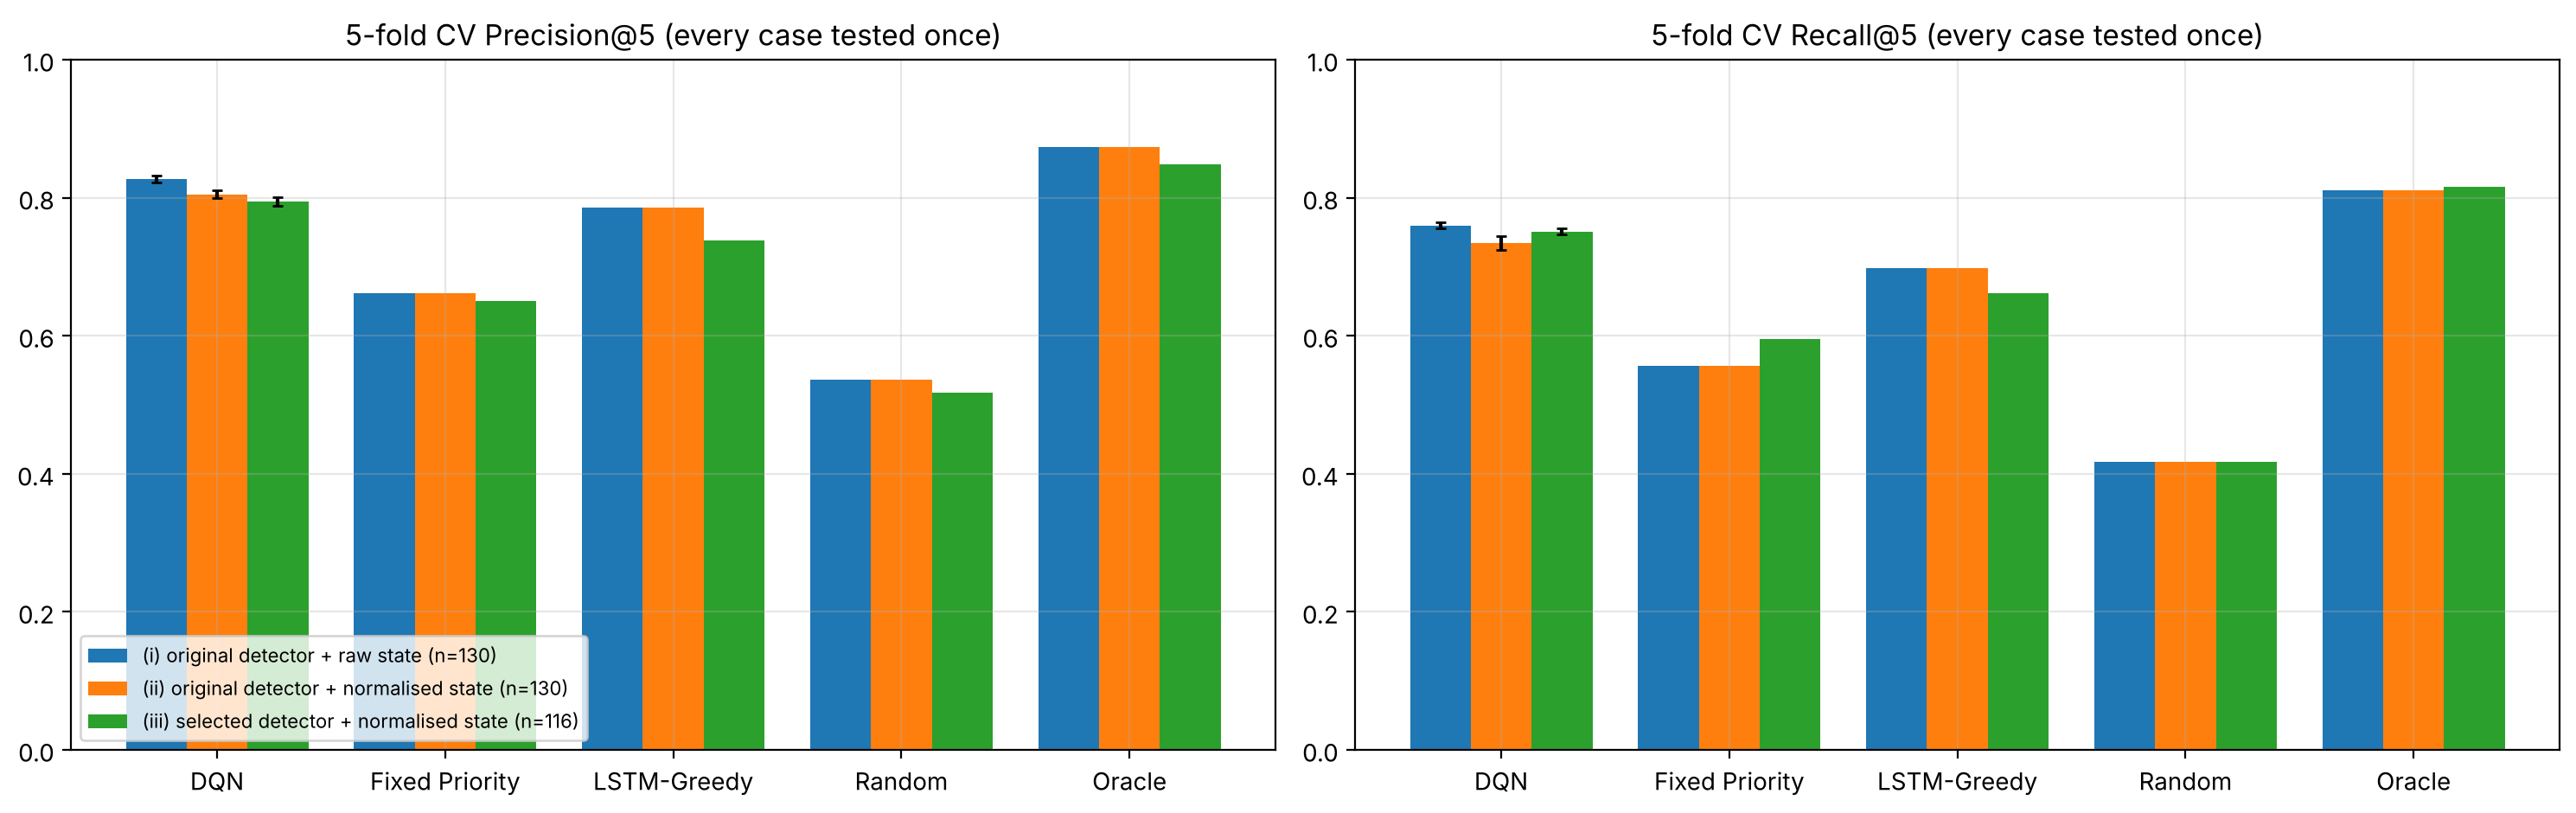

In [7]:
names = list(cv); x = np.arange(len(ORDER)); w = 0.8 / len(names)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
for j, n in enumerate(names):
    t = abl[abl.Config == n].set_index("Method").loc[ORDER]
    for a, m in zip(ax, ["Precision_at_5", "Recall_at_5"]):
        a.bar(x + (j - (len(names) - 1) / 2) * w, t[m], w, yerr=t[f"{m}_std"].where(t[f"{m}_std"] > 0), capsize=2, label=f"{n} (n={int(t.Cases.iloc[0])})")
for a, m in zip(ax, ["Precision@5", "Recall@5"]):
    a.set_xticks(x, ORDER); a.set_ylim(0, 1); a.set_title(f"5-fold CV {m} (every case tested once)")
ax[0].legend(fontsize=8, loc="lower left")
save_show("17_cv_ablation_budget5.png")

## 5. D — Budget sweep (3 / 5 / 7) for the best configuration
The configuration is chosen by the inner-validation reward of the DQN (test folds are never used for this choice).
Column names keep the "_at_5" suffix, but values are Precision/Recall at the given budget.

Inner-validation reward: {'(i) original detector + raw state': 3.667, '(ii) original detector + normalised state': 3.385}
Best configuration (chosen on inner validation): (i) original detector + raw state


I0000 00:00:1794216748.359107     760 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794216748.373342     763 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794216748.528014     761 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794216748.529411     759 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point ro

I0000 00:00:1794216751.080164     763 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794216751.106038     760 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794216751.338861     761 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794216751.363141     762 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794216751.403592     759 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


(i) original detector + raw state | budget 3: 130 cases, 25 DQN trainings in 4.1 min | mean inner-validation reward 2.802


I0000 00:00:1794216991.922451     812 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794216991.989166     809 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794216992.057232     808 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794216992.122413     811 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point ro

... (2 outputs left out)

I0000 00:00:1794216994.922595     808 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794216995.124665     811 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


(i) original detector + raw state | budget 7: 130 cases, 25 DQN trainings in 9.2 min | mean inner-validation reward 3.027


 Budget         Method  TotalReward  Precision_at_5  Recall_at_5  Precision_at_5_std
      3            DQN       2.5969          0.9328       0.5524              0.0102
      3 Fixed Priority       1.3692          0.7282       0.3454              0.0000
      3    LSTM-Greedy       2.0000          0.8333       0.4553              0.0000
      3         Oracle       2.9692          0.9949       0.6077              0.0000
      3         Random       0.2154          0.5359       0.2500              0.0000
      5            DQN       3.2738          0.8274       0.7599              0.0051
      5 Fixed Priority       1.6154          0.6615       0.5567              0.0000
      5    LSTM-Greedy       2.8615          0.7862       0.6975              0.0000
      5         Oracle       3.7385          0.8738       0.8103              0.0000
      5         Random       0.3590          0.5359       0.4167              0.0000
      7            DQN       2.7046          0.6932       0.8328 

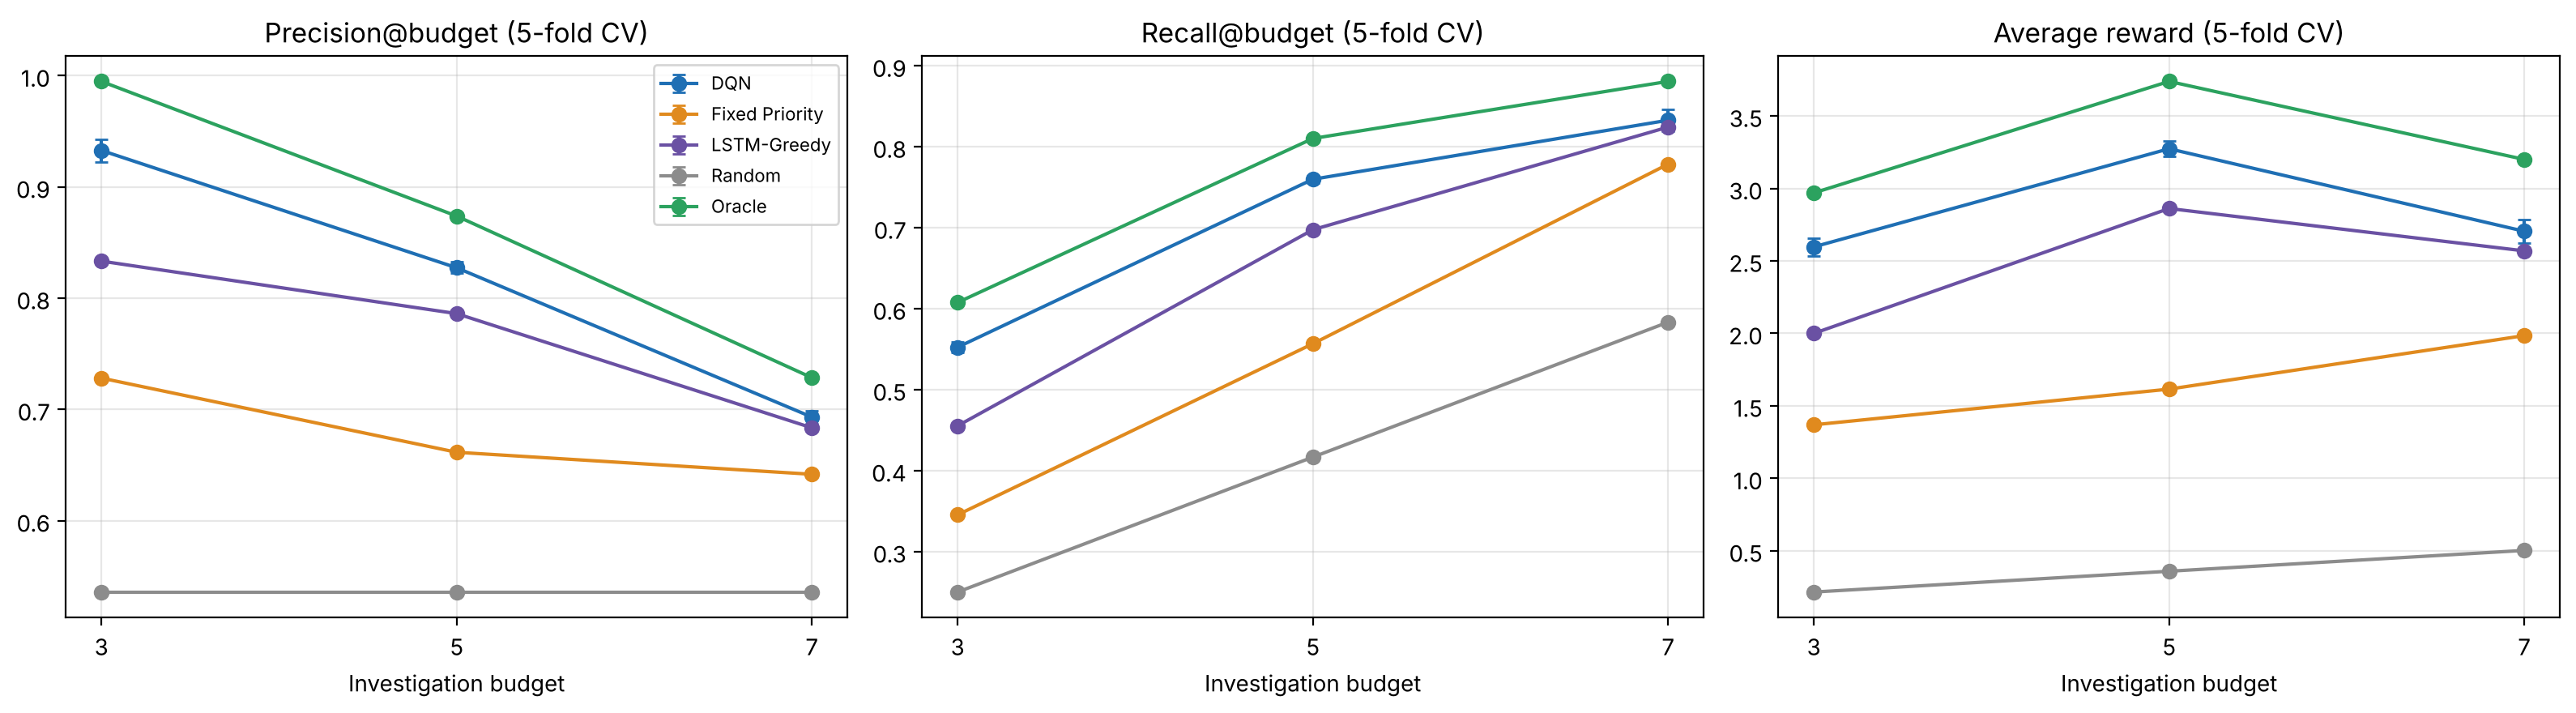

In [8]:
# Selection uses the inner-validation reward only (never the CV test folds). Configurations (i) and (ii)
# share the same 130 cases, so their validation rewards are directly comparable; (iii) is reported as an ablation.
cand = {n: cv[n].attrs["inner_val_reward"] for n in cv if n.startswith("(i)") or n.startswith("(ii)")}
print("Inner-validation reward:", {k: round(v, 3) for k, v in cand.items()})
BEST_CFG = max(cand, key=cand.get); print("Best configuration (chosen on inner validation):", BEST_CFG)
bc, bf = configs[BEST_CFG]
sweep = {5: cv[BEST_CFG]} | {b: run_cv(bc, bf, b, BEST_CFG) for b in [3, 7]}
sw = pd.concat([summarise(df).assign(Budget=b) for b, df in sweep.items()]).sort_values(["Budget", "Method"])
sw_tests = pd.concat([paired_tests(df).assign(Budget=b) for b, df in sweep.items()]).sort_values("Budget")
print(sw[["Budget", "Method", "TotalReward", "Precision_at_5", "Recall_at_5", "Precision_at_5_std"]].round(4).to_string(index=False))
print(); print(sw_tests.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
cols = {"DQN": "#1f6fb4", "Fixed Priority": "#e08a1e", "LSTM-Greedy": "#6a51a3", "Random": "#8c8c8c", "Oracle": "#2ca25f"}
for m in ORDER:
    d = sw[sw.Method == m].sort_values("Budget")
    for a, k in zip(ax, ["Precision_at_5", "Recall_at_5", "TotalReward"]):
        a.errorbar(d.Budget, d[k], yerr=d[f"{k}_std"].where(d[f"{k}_std"] > 0), marker="o", capsize=3, label=m, color=cols[m])
for a, t in zip(ax, ["Precision@budget", "Recall@budget", "Average reward"]):
    a.set_xticks([3, 5, 7]); a.set_xlabel("Investigation budget"); a.set_title(f"{t} (5-fold CV)")
ax[0].legend(fontsize=8)
save_show("18_budget_sweep_cv.png")

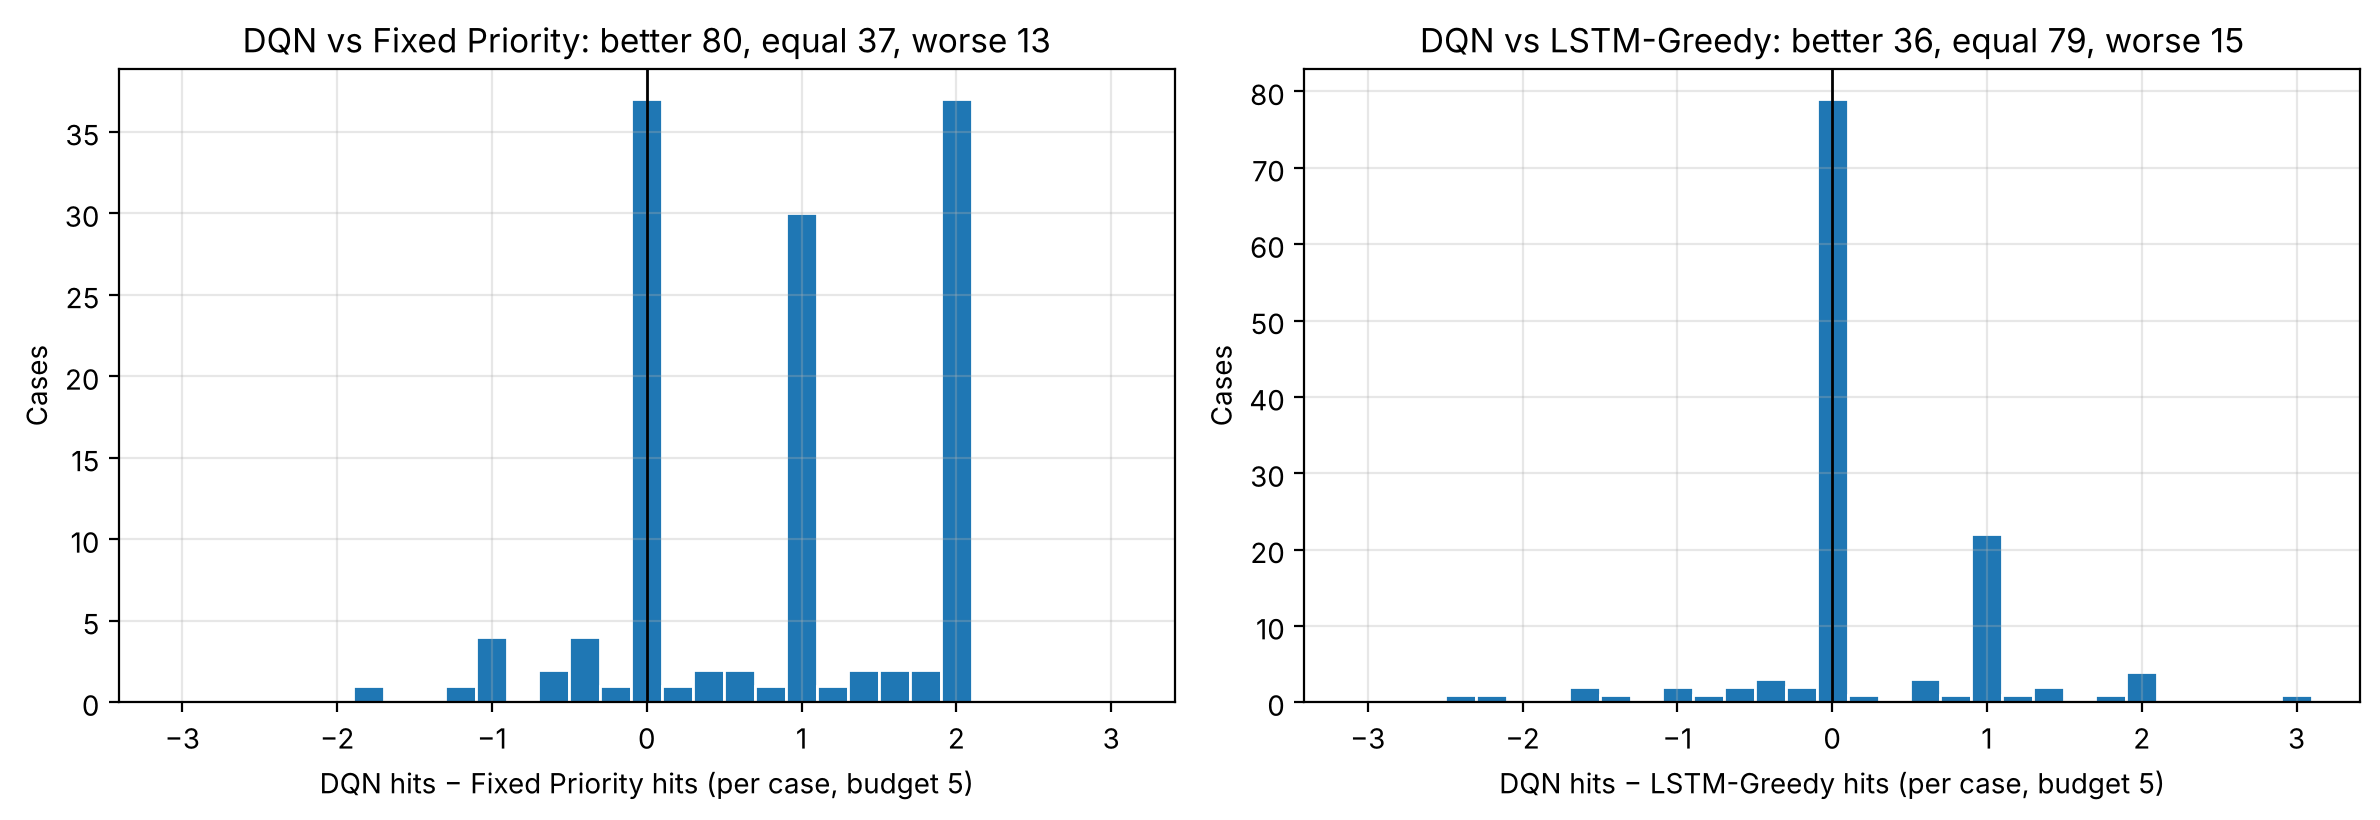

In [9]:
d5 = sweep[5]; dq = d5[d5.Method == "DQN"].groupby("Case")["Hits"].mean()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, o in zip(ax, ["Fixed Priority", "LSTM-Greedy"]):
    diff = dq - d5[d5.Method == o].set_index("Case")["Hits"].reindex(dq.index)
    a.hist(diff, bins=np.arange(-3.1, 3.2, 0.2), edgecolor="white"); a.axvline(0, color="black", lw=1)
    a.set_xlabel(f"DQN hits − {o} hits (per case, budget 5)"); a.set_ylabel("Cases")
    a.set_title(f"DQN vs {o}: better {int((diff > 1e-9).sum())}, equal {int((diff.abs() <= 1e-9).sum())}, worse {int((diff < -1e-9).sum())}")
save_show("19_cv_per_case_differences.png")

## 6. Save

In [10]:
det_cmp.to_csv(EXT / "detector_score_comparison.csv", index=False)
pd.DataFrame({"Channel": CHANNELS, "CleanTrainMedianError": ref_median}).to_csv(EXT / "channel_reference_errors.csv", index=False)
json.dump({"inner_val_reward": cand, "selected_score": BEST, "thresholds": thr, "cases_original": len(cases_orig), "cases_selected": len(cases_best),
           "best_config": BEST_CFG, "folds": K, "seeds": SEEDS, "hyperparameters": HP}, open(EXT / "extended_config.json", "w"), indent=2)
abl.to_csv(EXT / "cv_ablation_budget5.csv", index=False); tests.to_csv(EXT / "cv_ablation_tests.csv", index=False)
sw.to_csv(EXT / "cv_budget_sweep.csv", index=False); sw_tests.to_csv(EXT / "cv_budget_sweep_tests.csv", index=False)
pd.concat([df for df in cv.values()] + [sweep[3], sweep[7]]).to_csv(EXT / "cv_per_case_results.csv", index=False)
import shutil; shutil.rmtree(EXT / "models", ignore_errors=True)   # 250+ fold models are not needed; per-case results are kept
for f in sorted(EXT.iterdir()): print(f"{f.name:40s} {f.stat().st_size/1e3:8.1f} KB")

channel_reference_errors.csv                  0.3 KB
cv_ablation_budget5.csv                       2.9 KB
cv_ablation_tests.csv                         1.4 KB
cv_budget_sweep.csv                           2.3 KB
cv_budget_sweep_tests.csv                     1.1 KB
cv_per_case_results.csv                     608.1 KB
detector_score_comparison.csv                 0.8 KB
extended_config.json                          0.8 KB
